# Registros de emergencias hidrológicas y geológicas en Colombia

## Resumen
El extracto agregado contiene 2.309 filas de reportes de los cuatro grupos incluidos.

Un responsable de riesgos puede usar la composición de reportes para orientar una revisión de información pública.

**Alcance:** Son filas administrativas, no eventos únicos ni frecuencia de amenaza. Hay duplicaciones y problemas de ubicación; no estiman pérdidas aseguradas, exposición de activos ni probabilidad de inundación.

**Hallazgo del corte:** En el extracto, movimiento en masa representa 1.273 de 2.309 filas (55,1 %); el denominador son filas administrativas en cuatro grupos, no todos los riesgos.

## Contexto y método
Aplicación descriptiva reproducible. Las cantidades son agregadas a partir del archivo citado; no se infiere causalidad ni desempeño institucional.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import hashlib
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / '03-financial-risk').exists())
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})

## Datos
[UNGRD: Emergencias](https://www.datos.gov.co/Ambiente-y-Desarrollo-Sostenible/Emergencias-UNGRD/2343-nuqp): resumen de cuatro grupos hidrogeológicos, corte 2025, generado por el companion `10-climate-flood-and-physical-risk/data/official/ungrd-2025/`. La unidad es una fila administrativa resumida, no un evento único; no incluye todos los tipos de amenaza. Python con pandas, matplotlib y Jupyter; ejecutar desde el repositorio.

In [2]:
source = '03-financial-risk/07-financial-and-construction-risk-lab/02-construction-enterprise-risk/10-climate-flood-and-physical-risk/data/official/ungrd-2025/event_type_summary_2025.csv'
p = root / source
print('Archivo:', source, '\nSHA-256:', hashlib.sha256(p.read_bytes()).hexdigest())

Archivo: 03-financial-risk/07-financial-and-construction-risk-lab/02-construction-enterprise-risk/10-climate-flood-and-physical-risk/data/official/ungrd-2025/event_type_summary_2025.csv 
SHA-256: 72511b0d663bd741521e73981a6a63ce67c69f83a0d411d1b28b97ee00918cdb


## Resultados

Filas reportadas: 2309


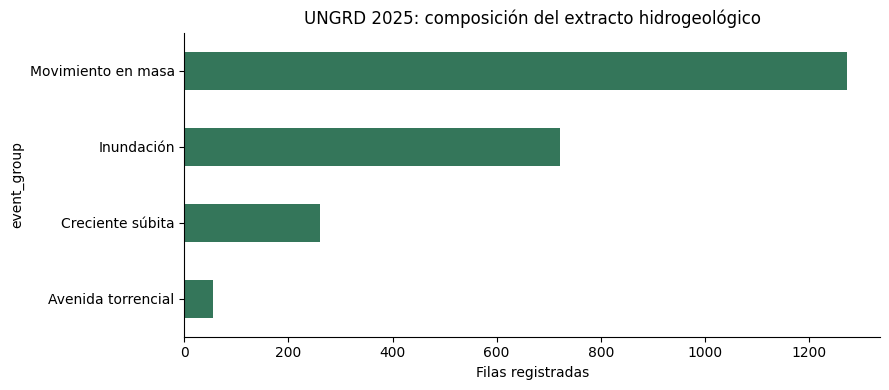

,event_group,report_rows,porcentaje
2,Movimiento en masa,1273,55.132092
3,Inundación,721,31.225639
1,Creciente súbita,260,11.260286
0,Avenida torrencial,55,2.381984


In [3]:
summary = pd.read_csv(root / source)
assert {'event_group','report_rows'}.issubset(summary.columns)
assert summary.event_group.is_unique and summary.report_rows.notna().all() and (summary.report_rows >= 0).all()
assert summary.report_rows.sum() > 0
summary['porcentaje'] = 100 * summary.report_rows / summary.report_rows.sum()
print('Filas reportadas:', summary.report_rows.sum())
summary.sort_values('report_rows').plot.barh(x='event_group', y='report_rows', legend=False, color='#34765a', xlabel='Filas registradas', title='UNGRD 2025: composición del extracto hidrogeológico')
plt.tight_layout(); plt.show()
summary.sort_values('report_rows', ascending=False)

## Variante: concentración de reportes dentro del extracto

Se calcula la proporción de filas en los cuatro grupos disponibles, la suma de sus participaciones al cuadrado y el número equivalente de categorías `1 / HHI`. Son indicadores descriptivos de la composición del extracto administrativo seleccionado; no son probabilidades de ocurrencia ni permiten comparar riesgos entre municipios. El [IPCC AR6](https://www.ipcc.ch/report/ar6/wg1/chapter/chapter-1/) distingue amenaza, exposición y vulnerabilidad: el resumen disponible solo contiene clases de reportes y no mide las otras dos dimensiones.

In [4]:
shares=summary.report_rows / summary.report_rows.sum()
hhi=float((shares**2).sum())
assert abs(shares.sum()-1)<1e-12 and 0 < hhi <= 1
print('HHI de las cuatro categorías:',round(hhi,4))
print('Número equivalente de categorías:',round(1/hhi,2))
print('Grupo de mayor participación:',summary.loc[shares.idxmax(),'event_group'], '| proporción:',round(shares.max()*100,2),'%')
summary.assign(participacion=shares).sort_values('participacion',ascending=False)[['event_group','report_rows','participacion']]

HHI de las cuatro categorías: 0.4147
Número equivalente de categorías: 2.41
Grupo de mayor participación: Movimiento en masa | proporción: 55.13 %


,event_group,report_rows,participacion
2,Movimiento en masa,1273,0.551321
3,Inundación,721,0.312256
1,Creciente súbita,260,0.112603
0,Avenida torrencial,55,0.023820


## Interpretación y límites
Son filas administrativas, no eventos únicos ni frecuencia de amenaza. Hay duplicaciones y problemas de ubicación; no estiman pérdidas aseguradas, exposición de activos ni probabilidad de inundación.

La cifra y la gráfica son descriptivas del corte disponible; las decisiones requieren datos propios, revisión de calidad y validación independiente.

**Acción siguiente:** contrastar con datos autorizados de la entidad, definir población y umbrales antes de cualquier decisión, y conservar la fecha y el hash del corte usado. Los controles de este notebook son de calidad local y no sustituyen revisión independiente.